# Limpeza e Tratamento de Dados — Ordens Preventivas ZM03

## 1. Contexto e Objetivos do Pipeline

O objetivo deste notebook é tratar a base de ordens de manutenção preventiva (`ZM03`) do sistema de Portas de Plataforma (PSDs), disponibilizada em `Ordens do SAP -Preventivas (ZM03).XLSX`. 

In [ ]:
import pandas as pd
import numpy as np
import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

path_base = "../../data/Preventiva/Ordens do SAP -Preventivas (ZM03).XLSX"
df_raw = pd.read_excel(path_base)
total_inicial = len(df_raw)

print(f"Registros lidos: {total_inicial:,} linhas x {df_raw.shape[1]} colunas")
print(f"IDs de 'Ordem' duplicados dentro da própria planilha: {df_raw['Ordem'].duplicated().sum()}")

Registros lidos: 590 linhas x 14 colunas
IDs de 'Ordem' duplicados dentro da própria planilha: 0


## 2. Diagnóstico e Tratamento de Valores Ausentes

Diferente dos alarmes (onde os nulos apareciam linha a linha), aqui o problema é em nível de **coluna inteira**: `Nº endereço` e `Prioridade` não têm nenhum valor preenchido em nenhuma das 590 ordens. Colunas 100% vazias não carregam informação nenhuma, então são removidas — não há nada para imputar.

In [ ]:
nulos_df = pd.DataFrame({
    'Quantidade_Nulos': df_raw.isnull().sum(),
    'Percentual (%)': (df_raw.isnull().sum() / len(df_raw) * 100).round(1),
})
print(nulos_df.to_string())

COLS_100_NULAS = nulos_df[nulos_df['Percentual (%)'] == 100.0].index.tolist()
print(f"\nColunas 100% nulas (sem nenhuma informação): {COLS_100_NULAS}")

df_semnulas = df_raw.drop(columns=COLS_100_NULAS).copy()
print(f"Colunas removidas: {len(COLS_100_NULAS)} | Colunas restantes: {df_semnulas.shape[1]}")

                      Quantidade_Nulos  Percentual (%)
Ordem                                0             0.0
Tipo de ordem                        0             0.0
Centro de trabalho                   0             0.0
Local de instalação                  0             0.0
Texto breve                          0             0.0
Plano de manutenção                  0             0.0
Nº endereço                        590           100.0
Status usuário                       0             0.0
Status do sistema                    0             0.0
Data-base do início                  0             0.0
Hr.início programada                 0             0.0
Data-base do fim                     0             0.0
Fim-base (hora)                      0             0.0
Prioridade                         590           100.0

Colunas 100% nulas (sem nenhuma informação): ['Nº endereço', 'Prioridade']
Colunas removidas: 2 | Colunas restantes: 12


## 3. Padronização e Parsing de Campos Temporais

`Data-base do início`/`fim` e `Hr.início programada`/`Fim-base (hora)` vieram em colunas separadas e foram agrupadas para virar um único `datetime`, para depois calcular a duração da ordem. Um achado importante, quando o horário programado é exatamente `24:00:00`, o Excel/pandas não consegue representar como `datetime.time` (o máximo é `23:59:59`) e grava como um `timedelta` de 1 dia. Ele precisa de tratamento explícito para não quebrar a conversão.

In [ ]:
def combinar_data_hora(data_col, hora_col):
    """Combina uma coluna de data com uma de hora, tratando o caso em que a
    hora é 24:00:00 (o Excel/pandas representa como timedelta de 1 dia em vez
    de um horário — não existe datetime.time(24,0))."""
    def to_timedelta(v):
        if pd.isna(v):
            return pd.NaT
        if isinstance(v, datetime.timedelta):
            return v
        return datetime.timedelta(hours=v.hour, minutes=v.minute, seconds=v.second)
    return pd.to_datetime(data_col) + hora_col.apply(to_timedelta)

n_overflow_inicio = df_semnulas['Hr.início programada'].apply(lambda v: isinstance(v, datetime.timedelta)).sum()
n_overflow_fim = df_semnulas['Fim-base (hora)'].apply(lambda v: isinstance(v, datetime.timedelta)).sum()
print(f"Horários gravados como 24:00:00 (virou timedelta de 1 dia): "
      f"{n_overflow_inicio} em 'Hr.início programada', {n_overflow_fim} em 'Fim-base (hora)'")

df_semnulas['DT_Inicio'] = combinar_data_hora(df_semnulas['Data-base do início'], df_semnulas['Hr.início programada'])
df_semnulas['DT_Fim']    = combinar_data_hora(df_semnulas['Data-base do fim'], df_semnulas['Fim-base (hora)'])
df_semnulas['duracao_h'] = (df_semnulas['DT_Fim'] - df_semnulas['DT_Inicio']).dt.total_seconds() / 3600

print(f"\nDuração da ordem (horas) — estatísticas:")
print(df_semnulas['duracao_h'].describe().round(1).to_string())

Horários gravados como 24:00:00 (virou timedelta de 1 dia): 0 em 'Hr.início programada', 2 em 'Fim-base (hora)'

Duração da ordem (horas) — estatísticas:
count     590.0
mean       72.0
std       104.3
min        -6.5
25%        12.0
50%        55.0
75%       103.0
max      2220.0


## 4. Decomposição de `Centro de trabalho` e `Local de instalação`, Identificação da Estação

A base não veio com uma coluna "Estação" pronta, para fazer ela, foi utilizado duas outras colunas:
* `Centro de trabalho`, no padrão `SP04I<EST>` (ex.: `SP04IBUT` → Butantã);
* `Local de instalação`, no padrão `SP04-6-PSD-<EST>` (ex.: `SP04-6-PSD-BUT` → Butantã).

`<EST>` deveria ser uma das 11 siglas da Linha 4 ( BUT, PIN, FAL, PTA, HIG, REP, LUZ, FRA, FRE, VSO, MBI), e na maioria das ordens os dois campos concordam. Mas em 120 das 590 linhas eles apontam para coisas diferentes, por dois motivos:

1. **`IENC01`** (em `Centro de trabalho`) não é uma estação, ele é um centro de trabalho genérico ("encarregado") usado em ordens de várias estações diferentes. Nesses casos, só o `Local de instalação` diz qual é a estação.
2. **`SP04IPVS`** (em `Centro de trabalho`) também não corresponde a nenhuma das 11 estações. O texto da ordem (`PORTAS PLATAFORMA - PVS`, às vezes `PRED PORTAS PLATAF` — prédio) mostra que é uma classificação genérica de manutenção, sem estação específica.

Por isso a estação final é resolvida em cascata, primeiro tenta `Local de instalação` primeiro (mais específico); se não achar, cai para `Centro de trabalho`; e se nenhum dos dois resolver para uma das 11 estações conhecidas, a ordem vira `GERAL`. Ela é mantida na base, só sinalizada, para quem for analisar por estação saber filtrar (107 ordens, 18% do total).


In [ ]:
df_semnulas['Estacao_Centro'] = df_semnulas['Centro de trabalho'].str.extract(r'SP04I([A-Z]{3})')
df_semnulas['Estacao_Local']  = df_semnulas['Local de instalação'].str.extract(r'SP04-6-PSD-([A-Z]{3})')

ESTACOES_LINHA4 = {'BUT', 'PIN', 'FAL', 'PTA', 'HIG', 'REP', 'LUZ', 'FRA', 'FRE', 'VSO', 'MBI'}

divergentes = df_semnulas[df_semnulas['Estacao_Centro'] != df_semnulas['Estacao_Local']]
print(f"'Centro de trabalho' e 'Local de instalação' apontam estações diferentes em {len(divergentes)} linhas.")

centros_nao_estacao = sorted(set(df_semnulas['Centro de trabalho']) - {f'SP04I{e}' for e in ESTACOES_LINHA4})
print(f"Códigos de 'Centro de trabalho' que não são nenhuma das 11 estações da Linha 4: {centros_nao_estacao}")

for centro in centros_nao_estacao:
    exemplos = df_semnulas.loc[df_semnulas['Centro de trabalho'] == centro, 'Texto breve'].unique()[:3]
    print(f"  {centro} ({(df_semnulas['Centro de trabalho']==centro).sum()} linhas) — ex.: {list(exemplos)}")

# Estação final: usa o Local (mais específico e correto quando o Centro é genérico
# como IENC01); cai para o Centro quando o Local não tem estação; PVS e casos sem
# nenhum dos dois viram 'GERAL' (ordem de prédio, não de uma estação específica).
df_semnulas['Estacao'] = df_semnulas['Estacao_Local'].fillna(df_semnulas['Estacao_Centro'])
df_semnulas.loc[~df_semnulas['Estacao'].isin(ESTACOES_LINHA4), 'Estacao'] = 'GERAL'

print(f"\nDistribuição final de estações:")
print(df_semnulas['Estacao'].value_counts().to_string())

'Centro de trabalho' e 'Local de instalação' apontam estações diferentes em 120 linhas.
Códigos de 'Centro de trabalho' que não são nenhuma das 11 estações da Linha 4: ['IENC01', 'SP04IPVS']
  IENC01 (47 linhas) — ex.: ['PSD - RACK DO PCC (AR COND.) FAL P1', 'PSD - RACK DO PCC (AR COND.) PTA P1', 'PSD - PORTAS PLATAF PIN - PLT1 - P3']
  SP04IPVS (92 linhas) — ex.: ['PSD - PORTAS PLATAFORMA - PVS P3', 'PSD - PORTAS PLATAFORMA - PVS P12', 'PSD - PORTAS PLATAFORMA - PVS P2']

Distribuição final de estações:
Estacao
GERAL    107
PTA       73
FAL       71
PIN       70
BUT       70
MBI       30
VSO       29
FRA       28
REP       28
HIG       28
FRE       28
LUZ       28


## 5. Tratamento de Inconsistências Temporais e Outliers

Duas categorias de problema na duração calculada:
1. **Durações negativas:** Em alguns casos o horário de fim registrado é anterior ao de início, geralmente uma ordem noturna (ex.: início 21:30) onde `Data-base do fim` não foi avançada para o dia seguinte.
2. **Outliers extremos (> 30 dias):** mesmo limite usado na limpeza dos alarmes, para consistência entre os dois pipelines. (houve somente um caso)

Junto com essas duas, foi removido também as ordens marcadas literalmente como **`ORDEM INDEVIDA`** pelo próprio SAP (o sistema já as invalidou) e foi sinalizado, sem remover, as ordens com status contendo `CANC` (canceladas), porque ainda são registros legítimos, só não representam manutenção de fato executada.</cell id="cell-8">


In [ ]:
n_negativas = (df_semnulas['duracao_h'] < 0).sum()
print(f"Ordens com duração negativa (fim registrado antes do início): {n_negativas}")

LIMITE_DIAS = 30
LIMITE_H = LIMITE_DIAS * 24
n_outliers = (df_semnulas['duracao_h'] > LIMITE_H).sum()
print(f"Ordens com duração acima de {LIMITE_DIAS} dias ({LIMITE_H:,}h): {n_outliers}")

n_ordem_indevida = (df_semnulas['Texto breve'] == 'ORDEM INDEVIDA').sum()
print(f"Ordens marcadas como 'ORDEM INDEVIDA' pelo próprio SAP: {n_ordem_indevida}")

n_cancelada = df_semnulas['Status usuário'].str.contains('CANC', na=False).sum()
print(f"Ordens com status contendo CANC (canceladas): {n_cancelada}")

df_final = df_semnulas[
    (df_semnulas['duracao_h'] >= 0) &
    (df_semnulas['duracao_h'] <= LIMITE_H) &
    (df_semnulas['Texto breve'] != 'ORDEM INDEVIDA')
].copy()
df_final['cancelada'] = df_final['Status usuário'].str.contains('CANC', na=False)

removidos = len(df_semnulas) - len(df_final)
print(f"\nRegistros removidos nesta etapa (duração inválida ou ordem indevida): {removidos}")
print(f"Total após esta etapa: {len(df_final):,}")
print(f"Das quais {df_final['cancelada'].sum()} seguem marcadas como canceladas (mantidas, mas sinalizadas em 'cancelada').")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
sns.histplot(df_semnulas['duracao_h'].clip(lower=0) + 1, log_scale=True, ax=ax1, color='#e15759', bins=25)
ax1.set_title('Duração Bruta (Escala Log)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Duração + 1 (horas, escala log)', fontsize=9)
ax1.set_ylabel('Ordens', fontsize=9)
ax1.axvline(LIMITE_H, color='black', linestyle='--', label=f'Corte de {LIMITE_DIAS} dias')
ax1.legend(fontsize=8)

sns.histplot(df_final['duracao_h'] + 1, log_scale=True, ax=ax2, color='#4c78a8', bins=25)
ax2.set_title(f'Duração Sanitizada (< {LIMITE_DIAS} dias)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Duração + 1 (horas, escala log)', fontsize=9)
ax2.set_ylabel('Ordens', fontsize=9)
plt.tight_layout()
plt.show()

Ordens com duração negativa (fim registrado antes do início): 17
Ordens com duração acima de 30 dias (720h): 1
Ordens marcadas como 'ORDEM INDEVIDA' pelo próprio SAP: 3
Ordens com status contendo CANC (canceladas): 13

Registros removidos nesta etapa (duração inválida ou ordem indevida): 21
Total após esta etapa: 569
Das quais 10 seguem marcadas como canceladas (mantidas, mas sinalizadas em 'cancelada').


## 6. Afunilamento Completo do Pipeline e Exportação

Pipeline concluído com sucesso! Dataset salvo em: ../../data/Preventiva/preventiva_zm03_limpa.csv
Registros: 569 | Colunas: 19


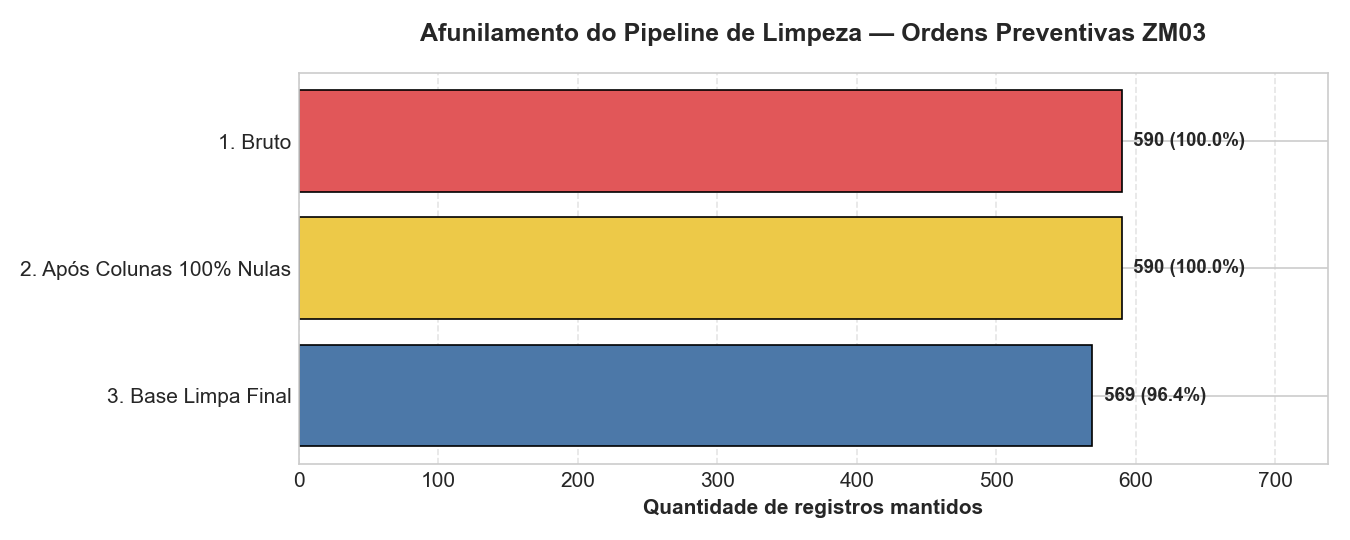

In [ ]:
etapas = ['1. Bruto', '2. Após Colunas 100% Nulas', '3. Base Limpa Final']
volumes = [total_inicial, len(df_semnulas), len(df_final)]

fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.barh(etapas[::-1], volumes[::-1], color=['#4c78a8', '#edc948', '#e15759'], edgecolor='black', linewidth=0.8)
for bar in bars:
    xval = bar.get_width()
    ax.text(xval + 8, bar.get_y() + bar.get_height()/2, f"{xval:,} ({(xval/total_inicial)*100:.1f}%)",
            ha='left', va='center', fontweight='bold', fontsize=9)
ax.set_title('Afunilamento do Pipeline de Limpeza — Ordens Preventivas ZM03', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Quantidade de registros mantidos', fontsize=10, fontweight='bold')
ax.set_xlim(0, total_inicial * 1.25)
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

output_path = "../../data/Preventiva/preventiva_zm03_limpa.csv"
df_final.to_csv(output_path, index=False, encoding='utf-8')
print(f"Pipeline concluído com sucesso! Dataset salvo em: {output_path}")
print(f"Registros: {len(df_final):,} | Colunas: {df_final.shape[1]}")

## Resumo

* Base com **590 ordens** em uma planilha (a segunda no repositório é idêntica, não foi usada).
* **2 colunas** removidas por não terem nenhum valor preenchido: `Nº endereço` e `Prioridade`.
* **2 ordens** com horário `24:00:00` precisaram de tratamento especial na conversão de data/hora.
* Estação de cada ordem identificada via `Local de instalação`/`Centro de trabalho`;*107 ordens (18%) não resolvem para nenhuma das 11 estações e ficam marcadas como `GERAL` (mantidas, não descartadas).
* **21 ordens removidas** por inconsistência: 17 com duração negativa, 1 com duração acima de 30 dias, 3 marcadas como `ORDEM INDEVIDA` pelo SAP.
* **13 ordens canceladas** (status `CANC`) mantidas na base, sinalizadas numa coluna `cancelada`.
* Resultado final: **569 ordens**, exportadas em `data/Preventiva/preventiva_zm03_limpa.csv`.